# ClientCo

## Churn : panel (client, lundi) + LightGBM
Churn à t si aucun achat dans [t, t+W[, avec W = min(90 j, 3 × médiane des écarts entre achats sur l'année précédente).

In [20]:
import os
import duckdb
import pandas as pd

DIR = os.path.expanduser("~/Downloads/Etude de Cas Data 2026 2/Data set")
CSV = f"{DIR}/dataset_sales_2026.csv"
DAILY = f"{DIR}/client_daily.parquet"

# 1) Une ligne par (client, jour d'achat) -> parquet de ~130 Mo (une seule passe sur le CSV, ~1 min)
con = duckdb.connect()
if not os.path.exists(DAILY):
    con.sql(f"""
    COPY (
      SELECT client_id, date_order AS day,
             sum(sales_net) AS sales, sum(quantity) AS qty, count(*) AS n_lines,
             avg((order_channel = 'online')::INT) AS share_online
      FROM read_csv('{CSV}', delim=';', header=true)
      GROUP BY 1, 2
    ) TO '{DAILY}' (FORMAT parquet)""")

# Table en mémoire + écart (en jours) avec l'achat précédent du client
con.sql(f"""
CREATE OR REPLACE TABLE d AS
SELECT *, day - lag(day) OVER (PARTITION BY client_id ORDER BY day) AS gap,
       min(day) OVER (PARTITION BY client_id) AS first_day
FROM '{DAILY}'""")
MIN_DAY, MAX_DAY = con.sql("SELECT min(day), max(day) FROM d").fetchone()

In [21]:
# 2) Panel : une ligne par (client, lundi t). Features sur [t-365, t[ ; label sur [t, t+W[
SNAPSHOT_SQL = """
WITH feat AS (
  SELECT client_id,
    $t - max(day)                                        AS recency,
    $t - min(first_day)                                  AS tenure,
    count(*)                                             AS n_days_365,
    count(*) FILTER (day >= $t - 90)                     AS n_days_90,
    count(*) FILTER (day >= $t - 30)                     AS n_days_30,
    coalesce(sum(sales) FILTER (day >= $t - 30), 0)      AS sales_30,
    sum(sales)                                           AS sales_365,
    coalesce(sum(sales) FILTER (day >= $t - 90), 0)      AS sales_90,
    coalesce(sum(sales) FILTER (day < $t - 90 AND day >= $t - 180), 0) AS sales_prev90,
    sum(qty)                                             AS qty_365,
    sum(n_lines)                                         AS lines_365,
    avg(share_online)                                    AS share_online,
    median(gap)                                          AS median_gap,
    stddev(gap)                                          AS std_gap,
    count(gap)                                           AS n_gaps
  FROM d WHERE day < $t AND day >= $t - 365
  GROUP BY client_id
),
win AS (  -- fenêtre de churn W = min(90, 3 * médiane des écarts), 90 si < 2 écarts
  SELECT *, CASE WHEN n_gaps >= 2 THEN least(90, 3 * median_gap) ELSE 90 END AS W FROM feat
),
ly AS (  -- saisonnalité : même période l'année dernière
  SELECT client_id,
    coalesce(sum(sales) FILTER (day < $t - 365), 0)      AS sales_30_ly,       -- [t-395, t-365[ = 30 derniers j, il y a 1 an
    count(*) FILTER (day >= $t - 365)                    AS n_days_next30_ly   -- [t-365, t-335[ = 30 prochains j, il y a 1 an
  FROM d WHERE day >= $t - 395 AND day < $t - 335
  GROUP BY client_id
),
nxt AS (  -- jours jusqu'au prochain achat (dans les 90 j)
  SELECT client_id, min(day) - $t AS days_to_next
  FROM d WHERE day >= $t AND day < $t + 90
  GROUP BY client_id
)
SELECT $t AS t, w.* EXCLUDE (sales_30),
  recency / median_gap               AS recency_ratio,
  sales_365 / n_days_365             AS basket_mean,
  sales_90 / nullif(sales_prev90, 0) AS sales_trend,
  month($t)                          AS month,
  -- NULL si l'historique ne remonte pas assez loin (données dispo depuis $start)
  CASE WHEN $t - 395 >= $start THEN sales_30 / nullif(coalesce(sales_30_ly, 0), 0) END AS sales_30_yoy,
  CASE WHEN $t - 365 >= $start THEN coalesce(n_days_next30_ly, 0) END                AS n_days_next30_ly,
  (days_to_next IS NULL OR days_to_next >= W)::INT AS churn
FROM win w LEFT JOIN nxt USING (client_id) LEFT JOIN ly USING (client_id)
WHERE recency < W                    -- on exclut les clients déjà churnés à t
"""

# Lundis toutes les 2 semaines, avec >= 6 mois d'historique ; le dernier sert au scoring (pas de label)
mondays = pd.date_range("2023-03-27", MAX_DAY, freq="14D").date
panel = pd.concat([con.execute(SNAPSHOT_SQL, {"t": t, "start": MIN_DAY}).df() for t in mondays], ignore_index=True)
panel["t"] = pd.to_datetime(panel.t)
panel["labeled"] = panel.t + pd.Timedelta(days=90) <= pd.Timestamp(MAX_DAY)  # sinon label censuré
print(panel.shape)
print(panel.groupby("labeled").agg(n=("churn", "size"), churn_rate=("churn", "mean"), t_min=("t", "min"), t_max=("t", "max")))

(3060232, 25)
               n  churn_rate      t_min      t_max
labeled                                           
False     482544    0.374503 2024-07-01 2024-09-09
True     2577688    0.290151 2023-03-27 2024-06-17


In [22]:
# 3) LightGBM avec split temporel + 90 j d'écart entre train et test (pas de fuite de label)
import lightgbm as lgb
from sklearn.metrics import average_precision_score, roc_auc_score

FEATURES = [c for c in panel.columns if c not in ("t", "client_id", "churn", "labeled")]
lab = panel[panel.labeled]
TEST_START = lab.t.max() - pd.Timedelta(days=91)               # ~3 derniers mois labellisés = test
train = lab[lab.t + pd.Timedelta(days=90) <= TEST_START]       # labels du train finis avant le test
test = lab[lab.t >= TEST_START]

model = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=63,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)
model.fit(train[FEATURES], train.churn)
p = model.predict_proba(test[FEATURES])[:, 1]

baseline = test.recency                                         # règle simple : plus la récence est grande, plus le risque est élevé
print(f"train {train.t.min().date()} -> {train.t.max().date()} ({len(train)}) | test {test.t.min().date()} -> {test.t.max().date()} ({len(test)})")
print(f"churn rate test : {test.churn.mean():.3f}")
print(f"PR-AUC  model {average_precision_score(test.churn, p):.3f} | baseline {average_precision_score(test.churn, baseline):.3f}")
print(f"ROC-AUC model {roc_auc_score(test.churn, p):.3f} | baseline {roc_auc_score(test.churn, baseline):.3f}")
print(pd.Series(model.feature_importances_, FEATURES).sort_values(ascending=False).head(10))

train 2023-03-27 -> 2023-12-18 (1603614) | test 2024-03-25 -> 2024-06-17 (503874)
churn rate test : 0.299
PR-AUC  model 0.552 | baseline 0.433
ROC-AUC model 0.745 | baseline 0.660
median_gap     3131
qty_365        2977
std_gap        2800
sales_90       2414
lines_365      2388
sales_365      2135
basket_mean    2112
tenure         1920
sales_trend    1772
month          1307
dtype: int32


In [23]:
# 4) Scoring : probabilité de churn au dernier lundi disponible
last = panel[panel.t == panel.t.max()].copy()
last["p_churn"] = model.predict_proba(last[FEATURES])[:, 1]
print(last.sort_values("p_churn", ascending=False)[["client_id", "recency", "median_gap", "W", "p_churn"]].head(10))

         client_id  recency  median_gap     W   p_churn
3024872    1190146       83         NaN  90.0  0.940321
3057998     451928       73       316.0  90.0  0.871249
3036316    1881537       87         NaN  90.0  0.870870
2991913    2269245       68         NaN  90.0  0.857310
3023375    1403736       89         NaN  90.0  0.852486
2995576     600541       67         2.0  90.0  0.852453
3008205    1291510       82         NaN  90.0  0.852410
3032341     580754       63         NaN  90.0  0.852169
3004538    1759160       73         NaN  90.0  0.850043
3023417     403771       63         NaN  90.0  0.849882


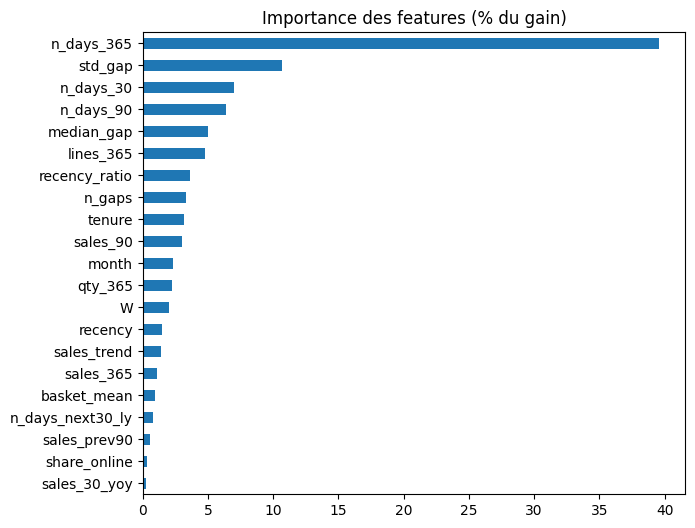

,gain_%,splits
n_days_365,39.6,903
std_gap,10.7,2800
n_days_30,7.0,609
n_days_90,6.4,828
median_gap,5.0,3131
lines_365,4.8,2388
recency_ratio,3.6,960
n_gaps,3.3,491
tenure,3.2,1920
sales_90,3.0,2414


In [24]:
import matplotlib.pyplot as plt

# Importance des features (gain = amélioration totale apportée par la feature dans les arbres)
imp = pd.DataFrame({
    "gain": model.booster_.feature_importance(importance_type="gain"),
    "splits": model.booster_.feature_importance(importance_type="split"),
}, index=FEATURES)
imp["gain_%"] = 100 * imp.gain / imp.gain.sum()
imp = imp.sort_values("gain_%", ascending=False)

imp["gain_%"].iloc[::-1].plot.barh(figsize=(7, 6), title="Importance des features (% du gain)")
plt.show()
imp[["gain_%", "splits"]].round(1)